# Install & imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

print('Imports OK')

Imports OK


# Reconnect paths, load features + split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
FEAT_DIR     = PROJECT_ROOT / 'data' / 'features'
SPLIT_DIR    = PROJECT_ROOT / 'data' / 'split'
FIG_DIR      = PROJECT_ROOT / 'figures'

d = np.load(str(FEAT_DIR / 'features_all.npz'))
node_features, y, subjects = d['node_features'], d['y'], d['subjects']

split_df   = pd.read_csv(SPLIT_DIR / 'subject_split.csv')
train_subj = split_df.loc[split_df['split']=='train','subject'].astype(str).values

train_mask = np.isin(subjects, train_subj)
nf_train, y_train, subj_train = node_features[train_mask], y[train_mask], subjects[train_mask]

print(f'Train set: {nf_train.shape}   PD: {int(y_train.sum())}   Control: {int((y_train==0).sum())}')

Mounted at /content/drive
Train set: (2709, 6, 60, 17)   PD: 1737   Control: 972


# Compute class weights (train only)

In [ ]:
n_pd = int(y_train.sum())
n_hc = int((y_train == 0).sum())
n_total = len(y_train)

# Standard inverse-frequency class weighting
class_weight_hc = n_total / (2 * n_hc)
class_weight_pd = n_total / (2 * n_pd)

class_weights = {0: class_weight_hc, 1: class_weight_pd}
print(f'Class weights (train, n={n_total}):')
print(f'  Control (0): {class_weight_hc:.4f}   (n={n_hc})')
print(f'  PD (1)     : {class_weight_pd:.4f}   (n={n_pd})')

np.save(str(SPLIT_DIR / 'class_weights.npy'), class_weights)

Class weights (train, n=2709):
  Control (0): 1.3935   (n=972)
  PD (1)     : 0.7798   (n=1737)


# Before/after class balance visualization

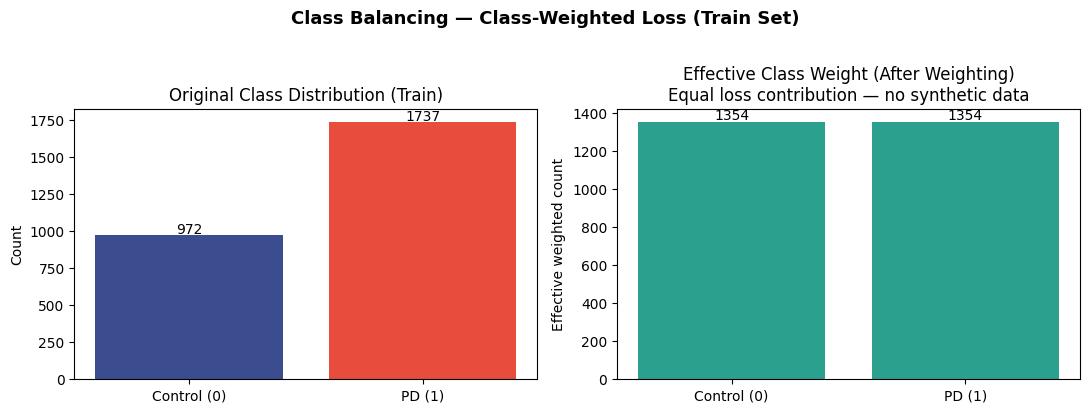


Note: class weighting adjusts the LOSS FUNCTION during training — it does not create
synthetic samples or alter the real data. The right panel shows how the two classes now
contribute EQUALLY to the training signal, despite the raw count imbalance shown on the left.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# "Original" — raw counts
axes[0].bar(['Control (0)', 'PD (1)'], [n_hc, n_pd], color=['#3b4d8f','#e74c3c'])
axes[0].set_title('Original Class Distribution (Train)')
axes[0].set_ylabel('Count')
for i, v in enumerate([n_hc, n_pd]):
    axes[0].text(i, v + 10, str(v), ha='center')

# "Effective" — counts scaled by their class weight, visualizing the REBALANCING EFFECT
# (no synthetic samples created — this shows how the loss function now treats each class)
effective_hc = n_hc * class_weight_hc
effective_pd = n_pd * class_weight_pd
axes[1].bar(['Control (0)', 'PD (1)'], [effective_hc, effective_pd], color=['#2ca08f','#2ca08f'])
axes[1].set_title('Effective Class Weight (After Weighting)\nEqual loss contribution — no synthetic data')
axes[1].set_ylabel('Effective weighted count')
for i, v in enumerate([effective_hc, effective_pd]):
    axes[1].text(i, v + 10, f'{v:.0f}', ha='center')

plt.suptitle('Class Balancing — Class-Weighted Loss (Train Set)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'train_class_balance.png'), dpi=130, bbox_inches='tight')
plt.show()

print('\nNote: class weighting adjusts the LOSS FUNCTION during training — it does not create')
print('synthetic samples or alter the real data. The right panel shows how the two classes now')
print('contribute EQUALLY to the training signal, despite the raw count imbalance shown on the left.')

# Save the train set

In [ ]:
np.savez_compressed(str(SPLIT_DIR / 'train_data.npz'),
                    node_features=nf_train, y=y_train, subjects=subj_train)
print(f'Saved train_data.npz: {nf_train.shape}')
print('Class weights saved separately in class_weights.npy — applied during training in Notebook 7.')

Saved train_data.npz: (2709, 6, 60, 17)
Class weights saved separately in class_weights.npy — applied during training in Notebook 7.
